# crs-sniffer showcase: Cairo Metro stations

Question: a file of Cairo Metro station coordinates arrives without a `crs` member. Which CRS does crs-sniffer say it is in, and which other CRSs can the numbers alone not rule out?

Data: OpenStreetMap station nodes (`railway=station` + `station=subway`), (c) OpenStreetMap contributors, ODbL. Run this notebook from the `showcase/` folder or the repository root.

In [1]:
import sys
from pathlib import Path

HERE = Path("showcase") if Path("showcase/make_showcase.py").exists() else Path(".")
sys.path.insert(0, str(HERE.resolve().parent / "src"))
sys.path.insert(0, str(HERE.resolve()))

from crs_sniffer import read_file, sniff
import make_showcase

data = HERE / "data" / "cairo_metro_stations.geojson"
points = read_file(data)  # [(x, y), ...] as stored in the file
print(len(points), "points; first:", points[0])

86 points; first: (31.2580736, 29.9598395)


In [2]:
matches = sniff(points)
for m in matches:
    print(m.code, "-", m.name)

EPSG:4326 - WGS 84 (lon/lat)
EPSG:27700 - OSGB36 / British National Grid
EPSG:3857 - WGS 84 / Pseudo-Mercator


In [3]:
# Same numbers with the axes swapped (lat, lon): still EPSG:4326, so the tool cannot detect a swap here.
print("swapped axes ->", sniff([(y, x) for x, y in points])[0].code)

swapped axes -> EPSG:4326


In [4]:
geojson = make_showcase.build_geojson(make_showcase.load_stations(data))
stations = [f for f in geojson["features"] if f["properties"]["kind"] == "station"]
print(f"{'station':<22} {'lon':>10} {'lat':>10}  best       candidates")
for f in stations[:8]:
    p = f["properties"]
    lon, lat = f["geometry"]["coordinates"]
    print(f"{(p['name_en'] or p['name'])[:22]:<22} {lon:>10.5f} {lat:>10.5f}  {p['best']:<10} {p['candidates']}")
print("...", len(stations), "stations; distinct candidate lists:", sorted({f['properties']['candidates'] for f in stations}))

station                       lon        lat  best       candidates
Maadi                    31.25807   29.95984  EPSG:4326  EPSG:4326, EPSG:27700, EPSG:3857
Omm El Misryeen          31.20796   30.00521  EPSG:4326  EPSG:4326, EPSG:27700, EPSG:3857
Behooth                  31.20034   30.03578  EPSG:4326  EPSG:4326, EPSG:27700, EPSG:3857
Dokki                    31.21204   30.03822  EPSG:4326  EPSG:4326, EPSG:27700, EPSG:3857
Opera                    31.22506   30.04196  EPSG:4326  EPSG:4326, EPSG:27700, EPSG:3857
Sadat                    31.23538   30.04395  EPSG:4326  EPSG:4326, EPSG:27700, EPSG:3857
Massara                  31.24502   30.07110  EPSG:4326  EPSG:4326, EPSG:27700, EPSG:3857
Rawd El-Farag            31.24535   30.08056  EPSG:4326  EPSG:4326, EPSG:27700, EPSG:3857
... 86 stations; distinct candidate lists: ['EPSG:4326, EPSG:27700, EPSG:3857']


mkdir -p failed for path /home/agent/.cache/matplotlib: [Errno 13] Permission denied: '/home/agent/.cache/matplotlib'


Matplotlib created a temporary cache directory at /tmp/matplotlib-eo09gtjm because there was an issue with the default path (/home/agent/.cache/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


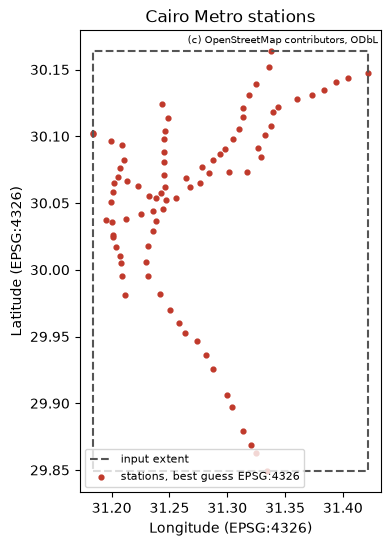

In [5]:
import math
import matplotlib.pyplot as plt

ext = geojson["features"][0]
ring = ext["geometry"]["coordinates"][0]
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([c[0] for c in ring], [c[1] for c in ring], "--", color="#555555", label="input extent")
ax.scatter([f["geometry"]["coordinates"][0] for f in stations],
           [f["geometry"]["coordinates"][1] for f in stations],
           s=12, color="#c0392b", label=f"stations, best guess {ext['properties']['best']}")
ax.set_aspect(1 / math.cos(math.radians(30.0)))
ax.set_xlabel("Longitude (EPSG:4326)")
ax.set_ylabel("Latitude (EPSG:4326)")
ax.set_title("Cairo Metro stations")
ax.legend(loc="lower left", fontsize=8)
ax.text(0.99, 0.99, "(c) OpenStreetMap contributors, ODbL", transform=ax.transAxes,
        ha="right", va="top", fontsize=7)
plt.show()